# 02e – Final model on 30 randomly sampled, unseen areas

The six test areas were chosen by hand and were looked at several times during development.
This notebook evaluates the **frozen** final model once on the independent set built in notebook 01d:
30 areas drawn at random on six continents, never used for training or for choosing anything.

**Order of work (must not be changed):**
1. 02d trains the candidates, 02c chooses the final setting on the validation set (`models/round3/inference_choice.json`).
2. This notebook first records a fingerprint (SHA-256) of the model files and of that choice, **before** the holdout data is loaded.
   If the notebook is run again and the model has changed, it stops.
3. The results are reported as they are. Nothing in the model or the settings is changed afterwards.

**Running it again** is only allowed with exactly the same frozen model and settings (checked with the fingerprint).
A second run does not tune anything; it only reproduces the numbers and saves more detail. The files of the first run
are kept as `*_first_run.*`, and the new numbers are compared with them at the end.

**What is reported:**
- overall accuracy, mIoU, per-class IoU and F1 (all 30 areas pooled)
- **95 % ranges from a bootstrap over areas**: neighbouring pixels are not independent, so the area is the unit that
  is resampled, not the pixel
- results per area, per continent and per month (seasonal effects)
- data availability: for how many of the checked land candidates Sentinel-1 data was usable
- a second bootstrap that resamples five areas **within each continent**, matching how the areas were drawn
- a record of the data, classes and notebooks that produced the results (`experiment_record.json`)

**Labels:** ESA WorldCover 2021, as in training. The numbers measure *agreement with WorldCover*, which itself has errors.

# 1. Setup

In [1]:
import sys
import subprocess
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").exists()

# keras-hub (for SegFormer) is installed WITHOUT its dependencies: a normal install
# pulls in another TensorFlow version and breaks the existing one.
# The keras-hub version must fit the installed Keras: 0.33.0 needs Keras >= 3.15,
# 0.24.0 works with Keras 3.8 - 3.14 (tested with TensorFlow 2.20 + Keras 3.11.2).
from importlib.metadata import version as package_version, PackageNotFoundError

keras_version = tuple(int(part) for part in package_version("keras").split(".")[:2])
KERAS_HUB = "0.33.0" if keras_version >= (3, 15) else "0.24.0"

try:
    installed = package_version("keras-hub")
except PackageNotFoundError:
    installed = None

if installed != KERAS_HUB:
    print(f"installing keras-hub {KERAS_HUB} (found: {installed}) for Keras {package_version('keras')}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--force-reinstall",
                    f"keras-hub=={KERAS_HUB}"], check=True)
    if "keras_hub" in sys.modules:
        raise RuntimeError("keras-hub was replaced - restart the kernel and run this cell again")

# small helpers keras-hub needs: downloads from Kaggle Models / Hugging Face (no TensorFlow dependency)
missing = []
for package in ["kagglehub", "huggingface_hub", "regex", "rich"]:
    try:
        package_version(package.replace("_", "-"))
    except PackageNotFoundError:
        missing.append(package)
if missing:
    print("installing", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

import keras_hub
print("keras-hub:", keras_hub.__version__)

installing keras-hub 0.24.0 (found: None) for Keras 3.11.2


installing ['kagglehub']


keras-hub: 0.24.0


In [2]:
import json
import time
import shutil
import hashlib
import warnings
from datetime import datetime, timezone

try:
    import pandas as pd
except ModuleNotFoundError:          # pandas is in requirements.txt; installed here only if it is missing
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pandas"], check=True)
    import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

GPUS = tf.config.list_physical_devices("GPU")
if GPUS:
    keras.mixed_precision.set_global_policy("mixed_float16")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| GPUs:", GPUS)

model_folder = Path("models/round3")
PLAN_VERSION = "v4_holdout"
holdout_folder = Path(f"holdout/patches_{PLAN_VERSION}")
result_folder = Path(f"holdout/evaluation_{PLAN_VERSION}")
result_folder.mkdir(parents=True, exist_ok=True)

# keep the files of the first run before anything is written again
for name in ["results.json", "per_area.csv", "confusion_per_area.npy"]:
    first_run = result_folder / name.replace(".", "_first_run.", 1)
    if (result_folder / name).exists() and not first_run.exists():
        shutil.copy(result_folder / name, first_run)
        print("kept the first run:", first_run)

TensorFlow: 2.20.0 | Keras: 3.11.2 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
kept the first run: holdout/evaluation_v4_holdout/results_first_run.json
kept the first run: holdout/evaluation_v4_holdout/per_area_first_run.csv
kept the first run: holdout/evaluation_v4_holdout/confusion_per_area_first_run.npy


# 2. Freeze the model (before looking at the holdout data)

In [3]:
choice = json.loads((model_folder / "inference_choice.json").read_text())
SELECTED = choice["selected_in_02d"]
MEMBERS = choice["models"]
TRANSFORMS = [tuple(t) for t in choice["transforms"]]
print("final setting from 02c:", " + ".join(MEMBERS), "|", choice["tta"], f"({len(MEMBERS) * len(TRANSFORMS)} predictions per patch)")


def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


files = [model_folder / "inference_choice.json", model_folder / "normalisation.json"]
for name in sorted(set(MEMBERS) | {SELECTED}):
    files.append(model_folder / name / "best.keras")
fingerprint = {str(path): sha256(path) for path in files}

freeze_path = result_folder / "frozen_model.json"
if freeze_path.exists():
    frozen = json.loads(freeze_path.read_text())
    if frozen["files"] != fingerprint:
        raise RuntimeError("The model or the 02c choice changed after the holdout evaluation was started. "
                           "Report the first result; do not tune on the holdout set.")
    print("same model as at the first run on", frozen["frozen_at"])
else:
    freeze_path.write_text(json.dumps({"frozen_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                                       "files": fingerprint}, indent=2))
    print("model frozen:", freeze_path)
for path, digest in fingerprint.items():
    print(f"  {digest[:16]}  {path}")

final setting from 02c: segformer_b3 + segformer_b2 + deeplabv3plus_resnet50 + unet_resnet50 | dihedral8 (32 predictions per patch)
same model as at the first run on 2026-11-07T21:34:05+00:00
  c60537db300b2bd0  models/round3/inference_choice.json
  dcef7b7c18280af9  models/round3/normalisation.json
  932fa0226abac6c1  models/round3/deeplabv3plus_resnet50/best.keras
  97674790b988ec9f  models/round3/segformer_b2/best.keras
  af5aaee65c9b95db  models/round3/segformer_b3/best.keras
  65db6d50d11e6efa  models/round3/unet_resnet50/best.keras


# 3. Models and holdout data

In [4]:
# same normalisation as in 02c: the statistics of all 55 training areas, used by every candidate model
norm = json.loads((model_folder / "normalisation.json").read_text())
models = {}
for name in sorted(set(MEMBERS) | {SELECTED}):
    models[name] = keras.models.load_model(model_folder / name / "best.keras", compile=False)
    own = model_folder / name / "normalisation.json"          # written by 02d for every experiment
    if own.exists():
        assert json.loads(own.read_text()) == norm, f"{name} was trained with other normalisation values"
    print("loaded", name)

class_info = json.loads((holdout_folder / "classes.json").read_text())
assert class_info["plan_version"] == PLAN_VERSION
CLASSES = class_info["classes"]
IGNORE = class_info["ignore"]
N_CLASSES = len(CLASSES)
model_classes = json.loads((model_folder / "model_info.json").read_text())["classes"]
assert CLASSES == model_classes, "holdout classes differ from the model classes"

x_all = np.load(holdout_folder / "holdout_x.npy", mmap_mode="r")
y_all = np.load(holdout_folder / "holdout_y.npy")
meta = pd.read_csv(holdout_folder / "holdout_meta.csv")
assert len(meta) == len(x_all) == len(y_all)
AREAS = list(dict.fromkeys(meta["area"]))
MONTHS = sorted(int(m) for m in meta["month"].unique())
print(f"{len(x_all)} patches from {len(AREAS)} areas, months {MONTHS}")
print(meta.groupby("continent")["area"].nunique().to_string())

loaded deeplabv3plus_resnet50
loaded segformer_b2
loaded segformer_b3
loaded unet_resnet50
4072 patches from 30 areas, months [1, 4, 7, 10]
continent
Africa           5
Asia             5
Europe           5
North America    5
Oceania          5
South America    5


# 4. Prediction

Same normalisation as in training and 02c, same flips/rotations and averaging as in 02c.
For every patch, the confusion matrix is kept per area and month; probabilities are not stored.

Two settings are evaluated: the **final setting** (main result) and, for comparison only, the model selected in 02d
alone without flips.

In [5]:
def normalise(x, norm):
    x = np.clip(x.astype(np.float32), np.float32(norm["clip_low"]), np.float32(norm["clip_high"]))
    if norm["add_ratio"]:
        x = np.concatenate([x, x[..., 0:1] - x[..., 1:2]], axis=-1)
    return (x - np.float32(norm["mean"])) / np.float32(norm["std"])


def dihedral(k, flip):
    def forward(a):
        a = a[:, :, ::-1] if flip else a
        return np.rot90(a, k, axes=(1, 2))

    def inverse(a):
        a = np.rot90(a, -k, axes=(1, 2))
        return a[:, :, ::-1] if flip else a

    return forward, inverse


def confusion(y_true, y_pred):
    valid = y_true != IGNORE
    index = N_CLASSES * y_true[valid].astype(np.int64) + y_pred[valid]
    return np.bincount(index, minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)


settings = {"final": [(m, t) for m in MEMBERS for t in TRANSFORMS]}
if settings["final"] != [(SELECTED, (0, False))]:
    settings["selected_alone"] = [(SELECTED, (0, False))]
needed = sorted({pair for pairs in settings.values() for pair in pairs})

BATCH = 16
matrices = {s: {} for s in settings}         # setting -> (area, month) -> confusion matrix
start = time.time()
for first in range(0, len(x_all), BATCH):
    x_raw = np.asarray(x_all[first:first + BATCH])
    y = y_all[first:first + BATCH]
    rows = meta.iloc[first:first + BATCH]

    x = normalise(x_raw, norm)
    probabilities = {}
    for name, t in needed:
        forward, inverse = dihedral(*t)
        p = models[name].predict_on_batch(np.ascontiguousarray(forward(x)))
        probabilities[(name, t)] = inverse(np.asarray(p, dtype=np.float32))

    for setting, pairs in settings.items():
        prediction = np.argmax(sum(probabilities[pair] for pair in pairs), axis=-1).astype(np.uint8)
        for i, (area, month) in enumerate(zip(rows["area"], rows["month"])):
            key = (area, int(month))
            matrices[setting][key] = matrices[setting].get(key, 0) + confusion(y[i], prediction[i])

    if first // BATCH % 50 == 0:
        print(f"{first + len(y)}/{len(x_all)} patches, {(time.time() - start) / 60:.1f} min", flush=True)
print(f"done in {(time.time() - start) / 60:.1f} min")

16/4072 patches, 0.8 min
816/4072 patches, 1.9 min
1616/4072 patches, 3.1 min
2416/4072 patches, 4.2 min
3216/4072 patches, 5.3 min
4016/4072 patches, 6.4 min
done in 7.3 min


# 5. Results

In [6]:
def scores(cm):
    cm = np.asarray(cm, dtype=np.float64)
    tp = np.diag(cm)
    actual = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    union = actual + predicted - tp
    iou = np.divide(tp, union, out=np.full(tp.shape, np.nan), where=union > 0)
    f1 = np.divide(2 * tp, actual + predicted, out=np.full(tp.shape, np.nan), where=(actual + predicted) > 0)
    return {"oa": tp.sum() / cm.sum(), "miou": np.nanmean(iou), "iou": iou, "f1": f1}


def per_area(setting):
    cms = {}
    for (area, month), cm in matrices[setting].items():
        cms[area] = cms.get(area, 0) + cm
    return np.stack([cms[a] for a in AREAS])        # shape (areas, classes, classes)


area_cms = {s: per_area(s) for s in settings}

# bootstrap over areas: draw 30 areas with replacement, pool their pixels, compute the scores; repeat 2000 times
B = 2000
rng = np.random.default_rng(0)
draws = rng.integers(0, len(AREAS), size=(B, len(AREAS)))


def low_high(values):
    with warnings.catch_warnings():          # a class missing in all areas gives NaN without a warning
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanpercentile(np.array(values), [2.5, 97.5], axis=0)


def bootstrap(cms):
    runs = [scores(cms[d].sum(axis=0)) for d in draws]
    return {"oa": low_high([r["oa"] for r in runs]), "miou": low_high([r["miou"] for r in runs]),
            "iou": low_high([r["iou"] for r in runs]), "f1": low_high([r["f1"] for r in runs])}


# second bootstrap: five areas drawn with replacement within each continent (as the holdout was sampled)
continent_of = dict(zip(meta["area"], meta["continent"]))
groups = [[i for i, a in enumerate(AREAS) if continent_of[a] == c] for c in dict.fromkeys(meta["continent"])]
group_rng = np.random.default_rng(1)
group_draws = [np.concatenate([group_rng.choice(g, size=len(g), replace=True) for g in groups]) for _ in range(B)]


def bootstrap_within_continents(cms):
    runs = [scores(cms[d].sum(axis=0)) for d in group_draws]
    return {"oa": low_high([r["oa"] for r in runs]), "miou": low_high([r["miou"] for r in runs]),
            "iou": low_high([r["iou"] for r in runs])}


pooled = {s: scores(area_cms[s].sum(axis=0)) for s in settings}
ranges = {s: bootstrap(area_cms[s]) for s in settings}
grouped = {s: bootstrap_within_continents(area_cms[s]) for s in settings}

print(f"{'setting':<16}{'OA':>8}{'95 % range':>18}{'mIoU':>8}{'95 % range':>18}   (bootstrap over all areas)")
for s in settings:
    p, r = pooled[s], ranges[s]
    print(f"{s:<16}{p['oa']:8.3f}{r['oa'][0]:10.3f} – {r['oa'][1]:.3f}{p['miou']:8.3f}{r['miou'][0]:10.3f} – {r['miou'][1]:.3f}")
print(f"{'':<16}{'':>8}{'95 % range':>18}{'':>8}{'95 % range':>18}   (bootstrap within continents)")
for s in settings:
    p, g = pooled[s], grouped[s]
    print(f"{s:<16}{p['oa']:8.3f}{g['oa'][0]:10.3f} – {g['oa'][1]:.3f}{p['miou']:8.3f}{g['miou'][0]:10.3f} – {g['miou'][1]:.3f}")

print(f"\nfor comparison, 6 test areas (02c): OA {choice['test_oa']:.3f}, mIoU {choice['test_miou']:.3f}")

print(f"\nfinal setting, per class{'':<6}{'IoU':>7}{'95 % range':>18}{'F1':>7}{'pixels %':>10}")
labelled = area_cms["final"].sum(axis=0).sum(axis=1)
for k, name in enumerate(CLASSES):
    p, r = pooled["final"], ranges["final"]
    print(f"{name:<30}{p['iou'][k]:7.3f}{r['iou'][0][k]:10.3f} – {r['iou'][1][k]:.3f}{p['f1'][k]:7.3f}"
          f"{100 * labelled[k] / labelled.sum():10.2f}")

setting               OA        95 % range    mIoU        95 % range   (bootstrap over all areas)
final              0.648     0.557 – 0.736   0.375     0.312 – 0.448
selected_alone     0.606     0.511 – 0.704   0.350     0.292 – 0.420
                                95 % range                95 % range   (bootstrap within continents)
final              0.648     0.564 – 0.728   0.375     0.313 – 0.441
selected_alone     0.606     0.517 – 0.691   0.350     0.290 – 0.415

for comparison, 6 test areas (02c): OA 0.699, mIoU 0.432

final setting, per class          IoU        95 % range     F1  pixels %
Trees (incl. mangroves)         0.724     0.583 – 0.829  0.840     32.92
Grassland / shrubland           0.438     0.306 – 0.566  0.609     34.74
Cropland                        0.517     0.335 – 0.667  0.682     17.57
Built-up                        0.358     0.100 – 0.419  0.528      0.93
Bare / sparse vegetation        0.338     0.111 – 0.604  0.505     10.97
Permanent water             

## Per area and per continent

The per-area mIoU only uses classes that occur in that area (in WorldCover or in the prediction).

In [7]:
patches_of = meta["area"].value_counts()

rows = []
for i, area in enumerate(AREAS):
    cm = area_cms["final"][i]
    s = scores(cm)
    truth = cm.sum(axis=1) / cm.sum()
    pred = cm.sum(axis=0) / cm.sum()
    row = {"area": area, "continent": continent_of[area], "patches": int(patches_of[area]),
           "oa": s["oa"], "miou": s["miou"],
           "main_class_worldcover": CLASSES[int(truth.argmax())], "share_worldcover_%": 100 * truth.max(),
           "main_class_predicted": CLASSES[int(pred.argmax())], "share_predicted_%": 100 * pred.max()}
    if "selected_alone" in settings:
        alone = scores(area_cms["selected_alone"][i])
        row["oa_selected_alone"], row["miou_selected_alone"] = alone["oa"], alone["miou"]
    rows.append(row)
table = pd.DataFrame(rows).sort_values("miou")
table.to_csv(result_folder / "per_area.csv", index=False)
pd.set_option("display.width", 200)
print(table.round(3).to_string(index=False))

print(f"\n{'continent':<16}{'areas':>6}{'OA':>8}{'mIoU':>8}{'lowest / highest area mIoU':>30}")
for continent in dict.fromkeys(meta["continent"]):
    index = [i for i, a in enumerate(AREAS) if continent_of[a] == continent]
    s = scores(area_cms["final"][index].sum(axis=0))
    m = table[table["continent"] == continent]["miou"]
    print(f"{continent:<16}{len(index):6d}{s['oa']:8.3f}{s['miou']:8.3f}{m.min():18.3f} / {m.max():.3f}")

             area     continent  patches    oa  miou    main_class_worldcover  share_worldcover_%     main_class_predicted  share_predicted_%  oa_selected_alone  miou_selected_alone
       Africa_003        Africa      144 0.017 0.003 Bare / sparse vegetation              99.880          Permanent water             97.960              0.012                0.002
         Asia_005          Asia      144 0.083 0.012    Grassland / shrubland              99.991          Permanent water             86.290              0.055                0.008
       Africa_007        Africa      144 0.269 0.073                 Cropland              86.746    Grassland / shrubland             81.306              0.346                0.092
North_America_010 North America      123 0.335 0.077    Grassland / shrubland              63.871 Bare / sparse vegetation             47.120              0.276                0.070
         Asia_002          Asia      144 0.375 0.082    Grassland / shrubland             

## Per month (seasonal effects)

In [8]:
print(f"{'month':<8}{'OA':>8}{'mIoU':>8}")
month_scores = {}
for month in map(int, MONTHS):
    cm = sum(cm for (area, m), cm in matrices["final"].items() if m == month)
    month_scores[month] = scores(cm)
    print(f"{month:<8}{month_scores[month]['oa']:8.3f}{month_scores[month]['miou']:8.3f}")

month         OA    mIoU
1          0.645   0.372
4          0.655   0.380
7          0.674   0.398
10         0.618   0.356


## Figures

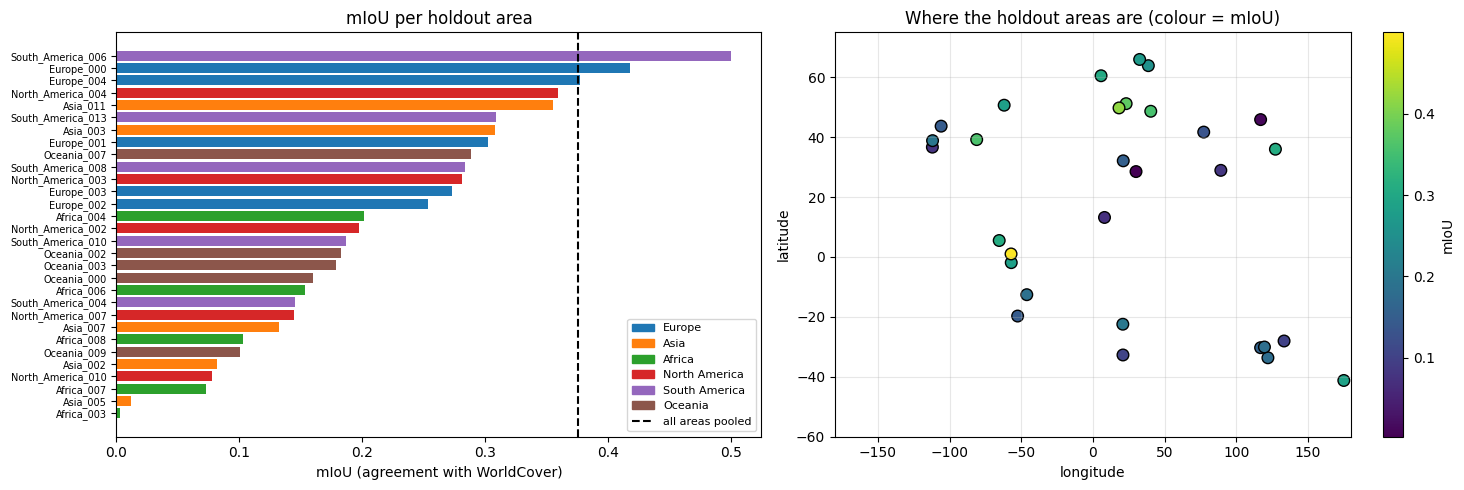

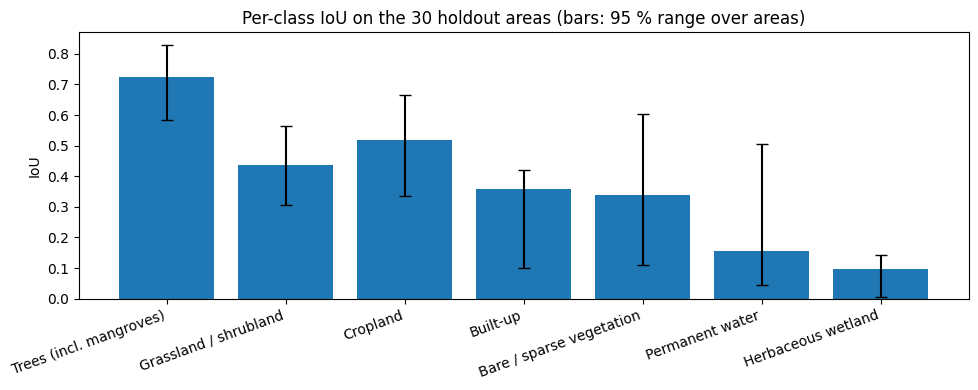

In [9]:
colors = dict(zip(dict.fromkeys(meta["continent"]), plt.cm.tab10.colors))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(table["area"], table["miou"], color=[colors[c] for c in table["continent"]])
line = axes[0].axvline(pooled["final"]["miou"], color="black", linestyle="--")
axes[0].set_xlabel("mIoU (agreement with WorldCover)")
axes[0].set_title("mIoU per holdout area")
axes[0].tick_params(axis="y", labelsize=7)
boxes = [plt.Rectangle((0, 0), 1, 1, color=v) for v in colors.values()]
axes[0].legend(boxes + [line], list(colors) + ["all areas pooled"], fontsize=8, loc="lower right")

points = table.merge(pd.DataFrame(json.loads(Path(f"holdout/config/accepted_{PLAN_VERSION}.json").read_text()))[["name", "lon", "lat"]],
                     left_on="area", right_on="name")
sc = axes[1].scatter(points["lon"], points["lat"], c=points["miou"], cmap="viridis", s=70, edgecolor="black")
axes[1].set_xlim(-180, 180)
axes[1].set_ylim(-60, 75)
axes[1].set_xlabel("longitude")
axes[1].set_ylabel("latitude")
axes[1].set_title("Where the holdout areas are (colour = mIoU)")
axes[1].grid(alpha=0.3)
fig.colorbar(sc, ax=axes[1], label="mIoU")
plt.tight_layout()
plt.savefig(result_folder / "holdout_per_area.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
positions = np.arange(N_CLASSES)
iou, (low, high) = pooled["final"]["iou"], ranges["final"]["iou"]
ax.bar(positions, iou, yerr=[iou - low, high - iou], capsize=4, color="tab:blue")
ax.set_xticks(positions, CLASSES, rotation=20, ha="right")
ax.set_ylabel("IoU")
ax.set_title(f"Per-class IoU on the {len(AREAS)} holdout areas (bars: 95 % range over areas)")
plt.tight_layout()
plt.savefig(result_folder / "holdout_per_class.png", dpi=150)
plt.show()

# 6. Data availability

How often was Sentinel-1 data usable at a random land point (from the checks in notebook 01d)?

In [10]:
radar_log = json.loads(Path(f"holdout/config/candidates_{PLAN_VERSION}.json").read_text())
availability = pd.crosstab(pd.Series([e["continent"] for e in radar_log.values()], name="continent"),
                           pd.Series([e["status"] for e in radar_log.values()], name="status"))
print(availability.to_string())
usable = sum(e["status"] == "accepted" for e in radar_log.values())
print(f"\nusable radar data for {usable} of {len(radar_log)} land candidates that were checked "
      f"({100 * usable / len(radar_log):.0f} %)")

status         accepted  low_coverage
continent                            
Africa                5             0
Asia                  5             1
Europe                5             0
North America         5             0
Oceania               5             2
South America         5             1

usable radar data for 30 of 34 land candidates that were checked (88 %)


# 7. Save

In [11]:
def as_list(a):
    return [None if np.isnan(v) else float(v) for v in np.atleast_1d(a)]


summary = {
    "plan_version": PLAN_VERSION,
    "areas": len(AREAS),
    "patches": int(len(x_all)),
    "final_setting": {"models": MEMBERS, "tta": choice["tta"]},
    "frozen_model": json.loads(freeze_path.read_text()),
    "bootstrap": {"unit": "area", "repetitions": B, "range": "2.5 - 97.5 percentile",
                  "over_all_areas": "30 areas drawn with replacement from all 30 (seed 0)",
                  "within_continents": "5 areas drawn with replacement within each continent (seed 1)"},
    "classes": CLASSES,
}
for s in settings:
    summary[s] = {
        "oa": float(pooled[s]["oa"]), "oa_range": as_list(ranges[s]["oa"]),
        "miou": float(pooled[s]["miou"]), "miou_range": as_list(ranges[s]["miou"]),
        "iou": as_list(pooled[s]["iou"]), "iou_low": as_list(ranges[s]["iou"][0]), "iou_high": as_list(ranges[s]["iou"][1]),
        "f1": as_list(pooled[s]["f1"]),
        "oa_range_within_continents": as_list(grouped[s]["oa"]),
        "miou_range_within_continents": as_list(grouped[s]["miou"]),
        "iou_low_within_continents": as_list(grouped[s]["iou"][0]),
        "iou_high_within_continents": as_list(grouped[s]["iou"][1]),
    }
summary["per_month"] = {str(m): {"oa": float(r["oa"]), "miou": float(r["miou"])} for m, r in month_scores.items()}
summary["test_set_for_comparison"] = {"oa": choice["test_oa"], "miou": choice["test_miou"]}
(result_folder / "results.json").write_text(json.dumps(summary, indent=2))

# per-area confusion matrices of both settings, stored together with the area names (rows = WorldCover, columns = prediction)
np.save(result_folder / "confusion_per_area.npy", area_cms["final"])
np.savez(result_folder / "confusion_per_area_all_settings.npz", areas=np.array(AREAS),
         continents=np.array([continent_of[a] for a in AREAS]), **{s: area_cms[s] for s in settings})
(result_folder / "area_order.json").write_text(json.dumps(
    [{"index": i, "area": a, "continent": continent_of[a]} for i, a in enumerate(AREAS)], indent=2))
print("saved in", result_folder, ":", sorted(p.name for p in result_folder.iterdir()))

saved in holdout/evaluation_v4_holdout : ['area_order.json', 'confusion_per_area.npy', 'confusion_per_area_all_settings.npz', 'confusion_per_area_first_run.npy', 'frozen_model.json', 'holdout_per_area.png', 'holdout_per_class.png', 'per_area.csv', 'per_area_first_run.csv', 'results.json', 'results_first_run.json']


# 8. Experiment record

Checksums of the holdout data and of the notebooks that made it, the class mapping and the frozen model, so the
results can be traced to exactly these files.

In [12]:
record_files = [holdout_folder / name for name in ["holdout_x.npy", "holdout_y.npy", "holdout_meta.csv", "classes.json"]]
record_files += sorted(Path("holdout/config").glob(f"*_{PLAN_VERSION}.json"))
record_files += [Path(name) for name in ["01d_holdout_random_areas.ipynb", "02c_tta_and_ensemble.ipynb"] if Path(name).exists()]

record = {
    "plan_version": PLAN_VERSION,
    "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "classes": CLASSES,
    "ignore": IGNORE,
    "worldcover_to_class": class_info["worldcover_to_class"],
    "sampling": class_info.get("sampling"),
    "frozen_model": json.loads(freeze_path.read_text()),
    "final_setting": {"models": MEMBERS, "transforms": [list(t) for t in TRANSFORMS]},
    "normalisation": norm,
    "environment": {"tensorflow": tf.__version__, "keras": keras.__version__, "keras_hub": keras_hub.__version__,
                    "numpy": np.__version__, "gpu": [g.name for g in GPUS]},
    "files_sha256": {str(path): sha256(path) for path in record_files},
}
(result_folder / "experiment_record.json").write_text(json.dumps(record, indent=2))
for path, digest in record["files_sha256"].items():
    print(f"  {digest[:16]}  {path}")

  dabdbbecfb1b7386  holdout/patches_v4_holdout/holdout_x.npy
  5abc5f7486d43388  holdout/patches_v4_holdout/holdout_y.npy
  1db71cb602240740  holdout/patches_v4_holdout/holdout_meta.csv
  3b45126d88fccdb4  holdout/patches_v4_holdout/classes.json
  cb54f211f62063e5  holdout/config/accepted_v4_holdout.json
  e5d24749e8fda2b0  holdout/config/candidates_v4_holdout.json
  5e11042a6a2c5171  holdout/config/checked_v4_holdout.json
  5de3c92599e19c6e  holdout/config/patches_v4_holdout.json
  0351c9525ce5ea38  01d_holdout_random_areas.ipynb
  7728a57a9946e08e  02c_tta_and_ensemble.ipynb


# 9. Comparison with the first run

Same frozen model and same data, so the numbers must be the same (tiny differences can come from the GPU).

In [13]:
first_path = result_folder / "results_first_run.json"
if first_path.exists():
    first = json.loads(first_path.read_text())
    for s in settings:
        if s not in first:
            print(f"{s}: not in the first run")
            continue
        old_iou = np.array([np.nan if v is None else v for v in first[s]["iou"]])
        print(f"{s:<16} OA {first[s]['oa']:.4f} -> {pooled[s]['oa']:.4f}   mIoU {first[s]['miou']:.4f} -> "
              f"{pooled[s]['miou']:.4f}   largest class IoU difference {np.nanmax(np.abs(old_iou - pooled[s]['iou'])):.4f}")
        assert abs(first[s]["oa"] - pooled[s]["oa"]) < 0.002 and abs(first[s]["miou"] - pooled[s]["miou"]) < 0.002, \
            "the results differ from the first run - check that the data and the model are unchanged"
else:
    print("this is the first run")

final            OA 0.6480 -> 0.6480   mIoU 0.3755 -> 0.3755   largest class IoU difference 0.0000
selected_alone   OA 0.6063 -> 0.6063   mIoU 0.3504 -> 0.3504   largest class IoU difference 0.0000
